# TP4 - Campo Magnético

**Materia:** Electricidad y Magnetismo

**Integrantes:**
* Fernanda Perez
* Tomas Aragusuku
* Jonathan Gomez
* Carla Rocca

## 1. Objetivo

_COMPLETAR_

## 2. Materiales y montaje

_COMPLETAR_

## 3. Introducción teórica

### Ley de Biot-Savart

Así como una carga en reposo genera un campo eléctrico, una carga en movimiento (una corriente $I$) genera un campo magnético $\vec{B}$. La ley de Biot-Savart da el aporte $d\vec{B}$ que genera un elemento diferencial de corriente $I\,d\vec{l}$ en un punto $P$ ubicado a una distancia $r$:

$$d\vec{B} = \frac{\mu_0}{4\pi}\,\frac{I\,d\vec{l}\times\hat{r}}{r^2}$$

donde $\mu_0$ es la permeabilidad del vacío, $d\vec{l}$ apunta en el sentido de la corriente, y $\hat{r}$ es el versor que va desde el elemento de corriente hasta $P$. El producto vectorial $d\vec{l}\times\hat{r}$ es el que define la **dirección** de $d\vec{B}$: siempre perpendicular tanto al cable como a $\hat{r}$.

### Regla de la mano derecha

Para saber el sentido de $\vec{B}$ sin calcular el producto vectorial, se usa la regla de la mano derecha: enroscando los dedos en el sentido en el que circula la corriente, el pulgar indica el sentido del campo magnético generado.

### Principio de superposición

El campo total en un punto no lo genera un único elemento de corriente, sino **todo** el circuito. Por eso el campo total es la suma (integral) de los aportes $d\vec{B}$ de cada elemento:

$$\vec{B} = \int d\vec{B} = \int \frac{\mu_0}{4\pi}\,\frac{I\,d\vec{l}\times\hat{r}}{r^2}$$

### Caso 1: cable conductor infinito

Para un cable recto e infinito, integrando la expresión anterior a lo largo de todo el cable se obtiene un resultado simple, que depende solo de la distancia $r$ al cable:

$$B = \frac{\mu_0 I}{2\pi r}$$

El campo es inversamente proporcional a $r$, y directamente proporcional a $I$.

### Caso 2: espira circular (campo sobre el eje)

Para una espira circular de radio $d$, el comportamiento es distinto. Tomamos un punto $P$ sobre el eje de la espira (perpendicular al plano de la espira, pasando por su centro), a una distancia $z$ del centro:

<p align="center">
  <img src="imagenes/campo.jpeg" width="70%">
</p>
<p align="center"><em>Geometría de la espira: el elemento $I\,d\vec{l}$ genera $d\vec{B}$ en P, con una componente $dB_y$ que se cancela por simetría y una componente axial $dB_x$ que sobrevive al integrar (acá llamada $d$ en vez de $R$, y $z$ en vez de $x$).</em></p>

Cada elemento $d\vec{l}$ de la espira está a la misma distancia $r=\sqrt{z^2+d^2}$ de $P$, y genera un $d\vec{B}$ con una componente a lo largo del eje y otra perpendicular a él. Por la simetría de la espira, las componentes perpendiculares de elementos opuestos se cancelan entre sí al sumarlas (superposición), y solo sobreviven las componentes a lo largo del eje. Integrando esas componentes sobre toda la espira:

$$\vec{B} = \frac{\mu_0 I}{2}\,\frac{d^2}{\left(z^2+d^2\right)^{3/2}}\,\hat{k}$$

con $\hat{k}$ en la dirección del eje. En el centro de la espira ($z=0$) esto se reduce a:

$$\vec{B} = \frac{\mu_0 I}{2d}\,\hat{k}$$

A diferencia del cable infinito, acá el campo **no diverge** cerca del centro: es máximo en $z=0$ y decae de forma simétrica a medida que $P$ se aleja hacia cualquiera de los dos lados, dando una curva en forma de campana (se grafica a continuación).

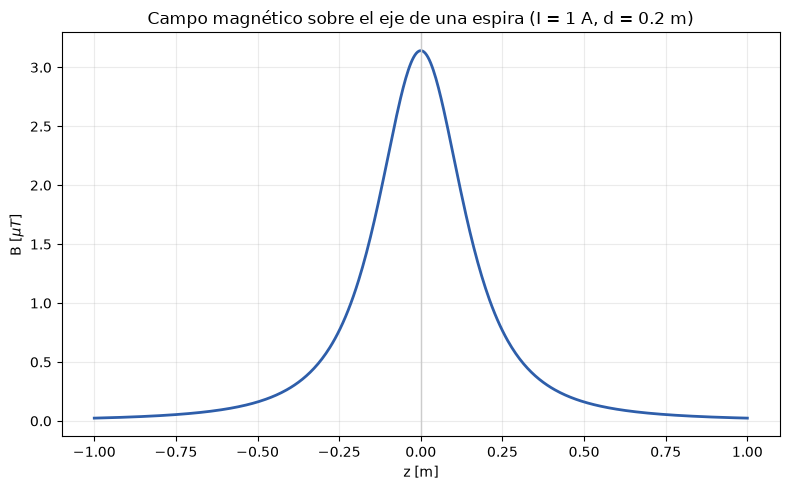

B en el centro (z=0) = 3.142 uT


In [1]:
import numpy as np
import matplotlib.pyplot as plt

mu0 = 4 * np.pi * 1e-7   # permeabilidad del vacío [T.m/A]

I = 1      # corriente [A]
d = 0.2    # radio de la espira [m]

z = np.linspace(-5 * d, 5 * d, 500)                  # distancia a lo largo del eje [m]
B = (mu0 * I * d**2) / (2 * (z**2 + d**2)**1.5)       # campo sobre el eje [T]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(z, B * 1e6, color="#2E5EAA", linewidth=2)
ax.axvline(0, color="0.8", linewidth=1)
ax.set_xlabel("z [m]")
ax.set_ylabel(r"B [$\mu T$]")
ax.set_title(f"Campo magnético sobre el eje de una espira (I = {I} A, d = {d} m)")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

B_centro = mu0 * I / (2 * d)
print(f"B en el centro (z=0) = {B_centro*1e6:.3f} uT")

### Por qué la curva tiene forma de campana

El gráfico muestra cómo cambia $B$ a medida que el punto $P$ se aleja del centro de la espira, moviéndose sobre el eje. Es una campana por dos efectos que se combinan:

1. **La distancia a cada punto de la espira crece.** En el centro ($z=0$) cada elemento de la espira está a la distancia mínima posible, $r=d$. A medida que $z$ crece, esa distancia pasa a ser $r=\sqrt{z^2+d^2}$, siempre mayor que $d$. Como el campo cae con $1/r^2$, alejarse ya debilita el campo.
2. **La proyección sobre el eje empeora.** Como vimos, solo sobrevive la componente de cada $d\vec{B}$ a lo largo del eje (las componentes perpendiculares se cancelan por simetría). En el centro esa proyección es la más favorable; cuanto más lejos está $P$, más oblicuo queda el segmento que va del cable a $P$, y menos campo queda apuntando en la dirección del eje.

Los dos efectos combinados hacen que el campo caiga más rápido de lo que caería el de un cable infinito. Por eso la curva:

* tiene su **máximo en $z=0$** (con $I=1\,A$ y $d=0{,}2\,m$, $B=3{,}14\,\mu T$),
* es **simétrica**: no hay ninguna razón física para que el campo sea distinto a un lado o al otro de la espira,
* y **cae rápidamente a cero**: con $z=\pm 1\,m$ (cinco veces el radio) el campo ya es casi nulo.

Esa forma de campana es justamente lo que distingue a la espira del cable infinito: el cable nunca "se apaga" del todo (el campo decae como $1/r$, muy lentamente), mientras que la espira concentra su campo cerca del centro y lo pierde rápido apenas $P$ se aleja sobre el eje.

### Dos espiras: ¿qué pasa si las combinamos?

Ahora agregamos una segunda espira, igual a la primera (mismo radio $d$ y misma corriente $I$, circulando en el mismo sentido), coaxial con la primera y separada una distancia $l$. Conviene ubicar el origen $z=0$ en el punto medio entre las dos espiras, así cada una queda centrada en $z=\mp l/2$:

$$B_1(z) = \frac{\mu_0 I}{2}\,\frac{d^2}{\left(\left(z-\tfrac{l}{2}\right)^2+d^2\right)^{3/2}} \qquad B_2(z) = \frac{\mu_0 I}{2}\,\frac{d^2}{\left(\left(z+\tfrac{l}{2}\right)^2+d^2\right)^{3/2}}$$

(es la misma relación que habíamos visto con $z+l$, solo que acá el origen queda en el medio de las dos espiras en vez de en el centro de la primera, para que el gráfico quede simétrico.)

Por el principio de superposición, el campo total es la suma de los dos:

$$B_{total}(z) = B_1(z) + B_2(z)$$

Para que se note bien la interacción entre los dos campos (el "valle" entre los dos picos) elegimos una separación $l$ mayor que el radio $d$: con $d=0,2\,m$, usamos $l=2d=0,4\,m$. Si las espiras estuvieran mucho más juntas (l mucho menor que d) los dos picos se fundirían en uno solo; si estuvieran muchísimo más separadas, se verían como dos campanas independientes, casi sin interacción entre sí (de hecho, hay una separación particular, $l=d$, en la que el campo se vuelve casi plano en el medio — es la base de las bobinas de Helmholtz, pero no es el caso que graficamos acá).

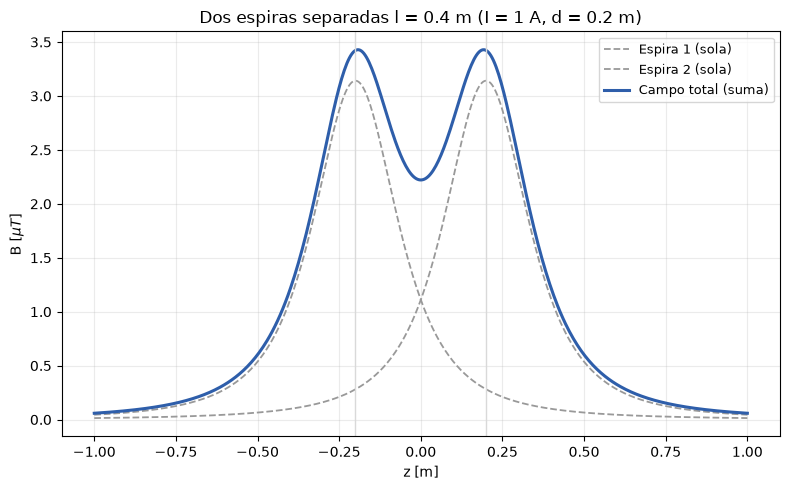

B en el centro de cada espira (z=+-l/2) = 3.423 uT
B en el punto medio (z=0)                = 2.221 uT


In [2]:
l = 2 * d   # separación entre las dos espiras [m]

def B_una_espira(z_rel):
    return (mu0 * I * d**2) / (2 * (z_rel**2 + d**2)**1.5)

z2 = np.linspace(-5 * d, 5 * d, 500)
B1 = B_una_espira(z2 - l / 2)
B2 = B_una_espira(z2 + l / 2)
B_total = B1 + B2

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(z2, B1 * 1e6, "--", color="0.6", linewidth=1.3, label="Espira 1 (sola)")
ax.plot(z2, B2 * 1e6, "--", color="0.6", linewidth=1.3, label="Espira 2 (sola)")
ax.plot(z2, B_total * 1e6, color="#2E5EAA", linewidth=2.2, label="Campo total (suma)")
ax.axvline(-l / 2, color="0.85", linewidth=1)
ax.axvline(l / 2, color="0.85", linewidth=1)
ax.set_xlabel("z [m]")
ax.set_ylabel(r"B [$\mu T$]")
ax.set_title(f"Dos espiras separadas l = {l} m (I = {I} A, d = {d} m)")
ax.grid(alpha=0.25)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

print(f"B en el centro de cada espira (z=+-l/2) = {B_una_espira(0)*1e6 + B_una_espira(l)*1e6:.3f} uT")
print(f"B en el punto medio (z=0)                = {2*B_una_espira(l/2)*1e6:.3f} uT")

Se forma la "M" que mencionaban: dos picos, uno por cada espira (donde cada una domina por estar más cerca), y un valle en el medio, donde ambas están relativamente lejos y ninguna compensa del todo la caída de la otra. Es la misma superposición que usamos siempre con Biot-Savart, solo que ahora los dos aportes que se suman no son infinitesimales ($d\vec{B}$ de un elemento de corriente) sino los campos completos de dos espiras enteras — el principio es el mismo en las dos escalas.

### Variando la separación entre espiras

¿Para cualquier separación $l$ se forma la M? No. Graficamos varias relaciones $l/d$ juntas, manteniendo siempre $I=1\,A$ y $d=0,2\,m$, para ver cómo cambia la forma del campo total a medida que se separan las espiras:

* Con $l$ chico (espiras muy juntas) los dos picos individuales se solapan tanto que se funden en uno solo, en $z=0$: **no hay M**.
* Con $l=d$ exactamente, el campo en el centro queda lo más "plano" posible (es la condición de Helmholtz) — tampoco hay un valle todavía, es el punto justo donde está por aparecer.
* A partir de $l>d$ empieza a formarse el valle en el centro, cada vez más marcado cuanto mayor es $l$: **ahí sí hay M**.

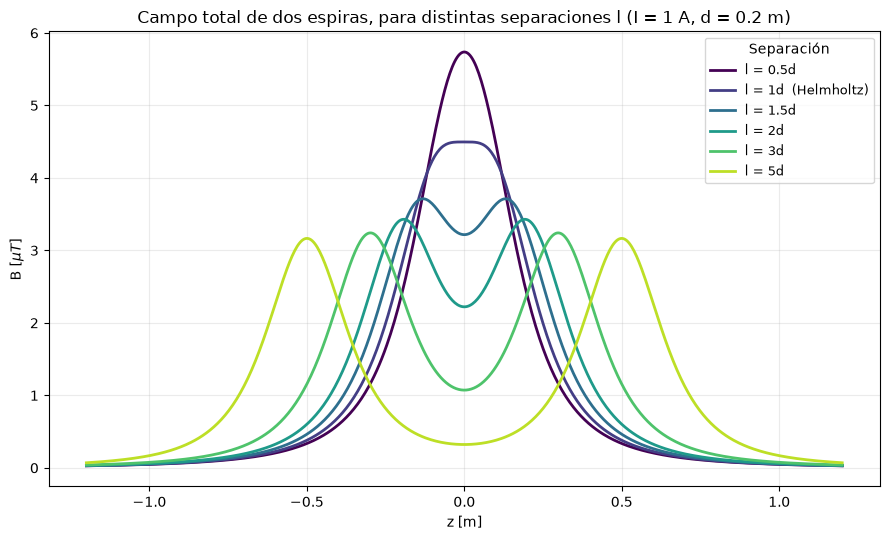

In [3]:
relaciones = [0.5, 1.0, 1.5, 2.0, 3.0, 5.0]   # l/d a comparar
colores = plt.cm.viridis(np.linspace(0, 0.9, len(relaciones)))

z3 = np.linspace(-6 * d, 6 * d, 600)

fig, ax = plt.subplots(figsize=(9, 5.5))
for factor, color in zip(relaciones, colores):
    l_i = factor * d
    B_i = B_una_espira(z3 - l_i / 2) + B_una_espira(z3 + l_i / 2)
    etiqueta = f"l = {factor:g}d" + ("  (Helmholtz)" if factor == 1.0 else "")
    ax.plot(z3, B_i * 1e6, color=color, linewidth=2, label=etiqueta)

ax.set_xlabel("z [m]")
ax.set_ylabel(r"B [$\mu T$]")
ax.set_title(f"Campo total de dos espiras, para distintas separaciones l (I = {I} A, d = {d} m)")
ax.grid(alpha=0.25)
ax.legend(fontsize=9, title="Separación")
fig.tight_layout()
plt.show()

Se ve la transición completa: con $l=0,5d$ y $l=d$ el campo tiene un único pico en el centro (sin valle); a partir de $l=1,5d$ ya aparece un mínimo local en $z=0$, que se hace cada vez más profundo (relativo a los picos) cuanto más se separan las espiras — hasta que para $l=5d$ casi se ven como dos campanas independientes, cada una pegada a su propia espira, con un valle bien marcado en el medio.

### Bobinas de Helmholtz

En muchos experimentos no alcanza con tener un campo magnético intenso en un único punto: hace falta una **zona** donde el campo sea lo más uniforme posible (constante), para que lo que se mida no dependa de la posición exacta del sensor. Dos espiras separadas la distancia justa logran eso en la región central — esa configuración se llama **bobinas de Helmholtz**.

**¿De dónde sale que esa distancia justa sea $l=d$?** Por la simetría de las dos espiras (misma corriente, mismo radio, una a cada lado del centro), la pendiente de $B_{total}(z)$ en $z=0$ ya es cero automáticamente: no importa $l$, ahí siempre hay un máximo o un mínimo local, nunca una pendiente distinta de cero. Esto se ve en todas las curvas del gráfico anterior — todas llegan "planas" (con derivada nula) a $z=0$, aunque unas sean picos y otras valles.

Lo que **no** es automático es que la curvatura también se anule ahí. Si tomamos la segunda derivada de $B_{total}(z)$ en $z=0$ e igualamos a cero (para que la curva no suba ni baje ni se curve, al menos cerca del centro), se llega a:

$$l = d$$

Es decir: **cuando la separación entre las espiras es igual al radio**, el campo en el centro no solo tiene pendiente nula (como en cualquier $l$), sino que además es lo más plano posible en un entorno del centro — ni pico ni valle, sino una meseta.

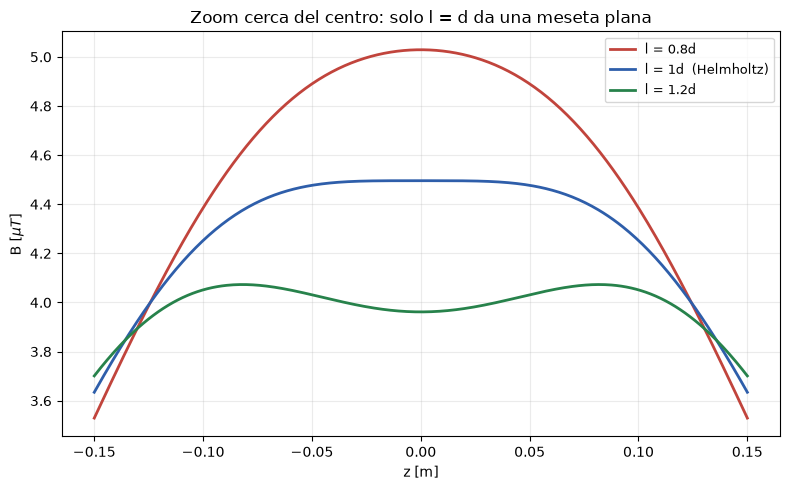

In [4]:
relaciones_h = [0.8, 1.0, 1.2]   # l/d cerca de la condición de Helmholtz
colores_h = ["#C1443C", "#2E5EAA", "#27824B"]

z4 = np.linspace(-0.15, 0.15, 400)

fig, ax = plt.subplots(figsize=(8, 5))
for factor, color in zip(relaciones_h, colores_h):
    l_i = factor * d
    B_i = B_una_espira(z4 - l_i / 2) + B_una_espira(z4 + l_i / 2)
    etiqueta = f"l = {factor:g}d" + ("  (Helmholtz)" if factor == 1.0 else "")
    ax.plot(z4, B_i * 1e6, color=color, linewidth=2, label=etiqueta)

ax.set_xlabel("z [m]")
ax.set_ylabel(r"B [$\mu T$]")
ax.set_title("Zoom cerca del centro: solo l = d da una meseta plana")
ax.grid(alpha=0.25)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

Con el zoom cerca del centro se nota la diferencia: con $l=0,8d$ el campo ya viene cayendo desde $z=0$ (es un pico, no una meseta); con $l=1,2d$ pasa lo opuesto, el campo sube un poco antes de empezar a bajar (ya es parte de un valle, aunque todavía muy leve). Con $l=d$ exactamente, el campo se mantiene prácticamente constante en todo ese entorno — es la separación que usan en la práctica las bobinas de Helmholtz para generar una región de campo uniforme, útil por ejemplo para calibrar instrumentos o cancelar el campo magnético terrestre en una zona del laboratorio.

## 4. Procedimiento experimental

_COMPLETAR_

## 5. Mediciones y resultados

_COMPLETAR_

## 6. Conclusiones

_COMPLETAR_